# Other-country PM2.5 scrapers (OpenAQ)

Downloads hourly PM2.5 of stations in Vietnam, Thailand, Indonesia and Malaysia, and writes them into `data/Other Countries/<country>/<city>/` in the **same layout as the Manila data**
(`sensors/openaq_<id>_<name>.csv` with the columns `location_name, location_id, sensor_id, utc_timestamp, local_timestamp, pm25_value, parameter, unit`, and `locations.csv`).
These are the source stations for transfer learning (the temporal side: PM2.5 history only; no weather, no morphology).

**The one site scraped: the OpenAQ API v3** (`https://api.openaq.org/v3`): `/locations` to find the PM2.5 stations of a city, `/sensors/{id}/hours` for their hourly values.
OpenAQ is the same network the Manila `openaq_*` files came from. The Zenodo "HCMC / Bangkok hourly air quality" datasets are **not** used: they are CAMS model output served by Open-Meteo, not measurements.

**You need a free API key** (60 requests a minute, 2,000 an hour): register at <https://explore.openaq.org/register>, then set it **in the environment** before opening the notebook:

```powershell
$env:OPENAQ_API_KEY =       # PowerShell; the notebook never reads or stores it in a file
```

Run the cells top to bottom. `DRY_RUN = True` (the default) only lists the stations and estimates the cost; set it to `False` to download. A download that stops (limit, closed laptop)
**resumes**: every sensor already in `_raw/` is kept. Check each provider's licence before redistributing the files.

## 1. Settings (the only cell you edit)

In [2]:
CITIES_TO_FETCH = ["vietnam/ho_chi_minh_city", "vietnam/hanoi", "thailand/bangkok", "indonesia/jakarta", "malaysia/kuala_lumpur"]   # the four capital regions plus Ho Chi Minh City (the largest city, not a capital); remove a line to skip it
START, END = "2023-01-01", "2026-11-19"     # the range to download (END is exclusive: 2026-11-19 includes all of 18 November; the Manila data runs 2023-01-01 to 2026-11-18)
MAX_STATIONS_PER_CITY = None                 # None = every PM2.5 station found; or a number to take only the ones with the longest record first
DRY_RUN = False                               # True: list stations and estimate the cost only. False: download
FORCE = False                                # True: download a sensor again although its file is in _raw/
TIME_LABEL = "from"                          # "from" = an hour is labelled by its start; "to" = by its end. Check one value against explore.openaq.org and
                                             # against a Manila file (data/Combined Dataset/.../sensors) before mixing the two networks
MIN_HOURS, MIN_MONTHS, MIN_COMPLETENESS = 6000, 12, 0.5     # a station is kept with >= 6,000 hours, readings in >= 12 different calendar months, and >= 50 % of the
                                             # hours between its first and last reading present (one wet-to-dry cycle at least)

## 2. Set up

In [3]:
import os, sys
from pathlib import Path
from dotenv import load_dotenv
import pandas as pd

HERE = Path.cwd() if (Path.cwd() / "openaq_scraper.py").exists() else Path.cwd() / "other-country-scrapers"
REPO = HERE.parent

# Load .env from the repo root (or fallback to current folder) BEFORE calling oa.OpenAQ()
load_dotenv(REPO / ".env", override=True)      # override: a key already in the environment (an old one) must not win over the .env file
load_dotenv(HERE / ".env", override=True)

sys.path.insert(0, str(HERE))
import importlib
import openaq_scraper as oa
oa = importlib.reload(oa)          # pick up edits to openaq_scraper.py without restarting the kernel

OUT = REPO / "data" / "Other Countries"
unknown = [c for c in CITIES_TO_FETCH if c not in oa.CITIES]
assert not unknown, f"unknown city {unknown}: add it to openaq_scraper.CITIES (bbox, UTM epsg, time zone) or use one of {list(oa.CITIES)}"

client = oa.OpenAQ()        # stops here with a clear message if OPENAQ_API_KEY is not set
print("key found; output folder:", OUT)

key found; output folder: c:\Users\perez\Downloads\urban-air\data\Other Countries


## 3. Find the stations
The PM2.5 stations inside each city's bounding box (mobile units are left out). Saved to `_cache/stations.csv`, so a later run does not ask again.

In [4]:
cache = OUT / "_cache"
cache.mkdir(parents=True, exist_ok=True)
stations_file = cache / "stations.csv"
known = pd.read_csv(stations_file) if stations_file.exists() else pd.DataFrame()
found = []
for city in CITIES_TO_FETCH:
    if len(known) and city in set(known["city"]):
        found.append(known[known["city"] == city])
        continue
    s = oa.discover_stations(client, city)
    print(f"{city}: {s['location_id'].nunique()} stations, {len(s)} PM2.5 sensors")
    found.append(s)
stations = pd.concat(found + ([known[~known["city"].isin(CITIES_TO_FETCH)]] if len(known) else []), ignore_index=True).drop_duplicates(["city", "sensor_id"])
stations.to_csv(stations_file, index=False)
selected = stations[stations["city"].isin(CITIES_TO_FETCH)].copy()
if MAX_STATIONS_PER_CITY:
    selected["_span"] = (pd.to_datetime(selected["last_utc"], utc=True) - pd.to_datetime(selected["first_utc"], utc=True)).dt.days
    selected = selected.sort_values("_span", ascending=False).groupby("city").head(MAX_STATIONS_PER_CITY).drop(columns="_span")
selected.groupby("city").agg(stations=("location_id", "nunique"), sensors=("sensor_id", "nunique"), first=("first_utc", "min"), last=("last_utc", "max"))

,stations,sensors,first,last
city,,,,
indonesia/jakarta,27,28,2016-01-30T01:00:00Z,2026-11-18T12:00:00Z
malaysia/kuala_lumpur,22,22,2022-11-03T21:00:00Z,2026-11-18T12:00:00Z
thailand/bangkok,202,272,2016-01-30T01:00:00Z,2026-11-18T12:00:00Z
vietnam/hanoi,38,38,2016-01-30T01:00:00Z,2026-11-18T12:35:00Z
vietnam/ho_chi_minh_city,20,20,2016-02-29T01:00:00Z,2026-11-18T12:00:00Z


## 4. What the download costs

In [5]:
cost = oa.plan(selected, START, END)
print(cost)
print(f"-> about {cost['requests']} requests; at the free limit that is about {cost['hours_at_free_limit']} h. Nothing is lost if it stops: it resumes.")
if DRY_RUN:
    print("DRY_RUN is True: nothing is downloaded. Set DRY_RUN = False in cell 1 and run cell 5.")

{'stations': 380, 'requests': 12748, 'hours_at_free_limit': 6.7, 'note': 'free keys: 60 requests a minute and 2,000 an hour; the download resumes where it stopped'}
-> about 12748 requests; at the free limit that is about 6.7 h. Nothing is lost if it stops: it resumes.


## 5. Download (resumable)

In [6]:
import time

if DRY_RUN:
    print("skipped (DRY_RUN)")
else:
    t0, todo = time.time(), selected.drop_duplicates("sensor_id")
    failed = []
    for i, (_, st) in enumerate(todo.iterrows(), 1):
        raw_dir = OUT / "_raw" / st["city"]
        had = (raw_dir / f"{st['sensor_id']}.csv").exists()
        try:
            oa.download_sensor(client, int(st["sensor_id"]), START, END, raw_dir, force=FORCE, first=st["first_utc"], last=st["last_utc"])
        except RuntimeError as err:                  # one sensor failing must not stop the others; run this cell again to retry it
            failed.append(int(st["sensor_id"])); print(f"  SKIPPED sensor {st['sensor_id']}: {str(err)[:230]}"); continue
        if not had or FORCE:
            print(f"[{i}/{len(todo)}] {st['city']} {st['location_name']} (sensor {st['sensor_id']}): {client.requests_made} requests, {(time.time() - t0) / 60:.1f} min")
    print("download finished" + (f"; {len(failed)} sensors skipped (run this cell again, it resumes): {failed}" if failed else ""))

  SKIPPED sensor 16312585: OpenAQ still refusing /sensors/16312585/hours after 6 tries (last status 500, x-ratelimit-remaining=None, reset in None s). 429 = the rate limit (2,000 requests an hour on a free key: wait, it clears by itself); 5xx = the server i
[69/380] thailand/bangkok Bang Khen District Office, Bangkok (sensor 1304254): 55 requests, 7.5 min
[70/380] thailand/bangkok Bang Khun Thian District Office, Bangkok (sensor 1304176): 88 requests, 9.1 min
  SKIPPED sensor 16312586: OpenAQ still refusing /sensors/16312586/hours after 6 tries (last status 500, x-ratelimit-remaining=None, reset in None s). 429 = the rate limit (2,000 requests an hour on a free key: wait, it clears by itself); 5xx = the server i
[72/380] thailand/bangkok Kasertsart University (sensor 1304409): 148 requests, 16.4 min
  SKIPPED sensor 16312715: OpenAQ still refusing /sensors/16312715/hours after 6 tries (last status 500, x-ratelimit-remaining=None, reset in None s). 429 = the rate limit (2,000 requests a

## 6. Keep the good stations and write the dataset
`station_quality.csv` in each city folder lists **every** station with the reason it was kept or dropped.

In [7]:
summary = []
for city in CITIES_TO_FETCH:
    sub = selected[selected["city"] == city]
    if not (OUT / "_raw" / city).exists() or sub.empty:
        print(f"{city}: nothing downloaded yet")
        continue
    table = oa.write_dataset(sub, OUT / "_raw" / city, OUT / city, START, END, MIN_HOURS, MIN_MONTHS, MIN_COMPLETENESS, TIME_LABEL)
    summary.append({"city": city, "sensors": len(table), "kept": int(table["kept"].sum()), "hours_kept": int(table.loc[table["kept"], "hours"].sum()) if "hours" in table else 0})
pd.DataFrame(summary)

,city,sensors,kept,hours_kept
0,vietnam/ho_chi_minh_city,20,1,16160
1,vietnam/hanoi,38,11,114423
2,thailand/bangkok,272,125,2497688
3,indonesia/jakarta,28,5,60132
4,malaysia/kuala_lumpur,22,2,24894


## 7. Look at what was kept

C:\Users\perez\AppData\Local\Temp\ipykernel_20964\3198479961.py:17: UserWarning: Glyph 3607 (\N{THAI CHARACTER THO THAHAN}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\perez\AppData\Local\Temp\ipykernel_20964\3198479961.py:17: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\perez\AppData\Local\Temp\ipykernel_20964\3198479961.py:17: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\perez\AppData\Local\Temp\ipykernel_20964\3198479961.py:17: UserWarning: Glyph 3627 (\N{THAI CHARACTER HO HIP}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\perez\AppData\Local\Temp\ipykernel_20964\3198479961.py:17: UserWarning: Glyph 3621 (\N{THAI CHARACTER LO LING}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\perez\AppData\Local\Temp\ipykernel_20964\3198479961.py:17: UserWarning: Glyph 3650 (\N{THAI CHARACTER SARA O}) 

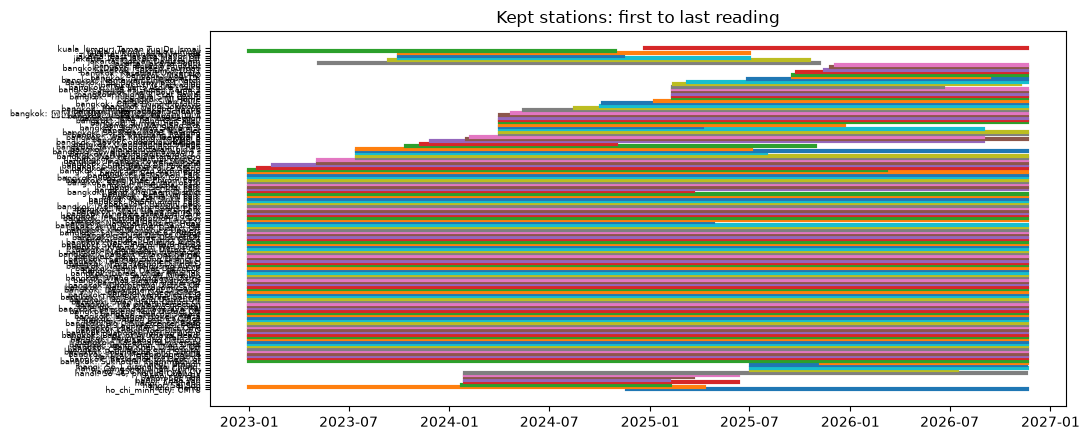

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4.5))
y, labels = 0, []
for city in CITIES_TO_FETCH:
    q = OUT / city / "station_quality.csv"
    if not q.exists():
        continue
    t = pd.read_csv(q)
    t = t[t["kept"]].sort_values("first")
    for _, r in t.iterrows():
        ax.plot([pd.Timestamp(r["first"]), pd.Timestamp(r["last"])], [y, y], lw=3)
        labels.append(f"{city.split('/')[1]}: {r['location_name'][:22]}")
        y += 1
ax.set_yticks(range(len(labels)), labels, fontsize=6)
ax.set_title("Kept stations: first to last reading")
fig.tight_layout()
fig.savefig(OUT / "kept_stations.png", dpi=150)
plt.show()

## What next

The folders under `data/Other Countries/` are read by the transfer-learning code (`model/transfer/`, see the README section on transfer learning) exactly like the Manila sensors.
Tests of the scraper itself (a fake API, no key needed): `python -m pytest other-country-scrapers/tests -q`.